In [37]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import random
import torch
import tqdm
import os

In [3]:
prod = lambda v: 1 if not v else v[-1] * prod(v[:-1])

n_choose_k = lambda n, k: prod(range(n-k+1, n+1)) // prod(range(1, k+1))
n_arranj_k = lambda n, k: prod(range(n-k+1, n+1))

In [92]:
ht_k_closest_to_mean = {4: -5.89, 6: -41.884, 8: -163.168}

In [2]:
CONFIG_FOLDER = "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/simulate_dfly_queue_sizes/configs/"

def compute_Z(h, buckets):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    Z = [[0 for j in range(cnt_groups)] for i in range(cnt_groups)]
    for row in buckets:
        for buck in row:
            for i in range(h):
                for j in range(i+1, h):
                    Z[min(buck[i], buck[j])][max(buck[i], buck[j])] += 1
    return Z

def get_score(h, buckets):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    Z = compute_Z(h, buckets)
    scor = 0
    for i in range(cnt_groups):
        for j in range(i+1, cnt_groups):
            scor -= abs(Z[i][j] - (h - 1))
    return scor

def build_default_config(h):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    buckets = [[[] for j in range(h)] for i in range(cnt_groups)]
    for src_group in range(cnt_groups):
        for dst_group in range(cnt_groups):
            if src_group != dst_group:
                src_sw = (dst_group - (1 if src_group < dst_group else 0)) // h
                dst_sw = (src_group - (0 if src_group < dst_group else 1)) // h
                buckets[src_group][src_sw].append(dst_group)
    return buckets

def read_buckets(h, fname):
    make_buckets = lambda v: [[v[j] for j in range(i*h, (i+1)*h)] for i in range(h)]
    with open(fname) as fin:
        return [make_buckets(list(map(int, line.strip().split()))) for line in fin.readlines()]
    
def get_random_buckets(h, nt):
    cnt_groups = h**2 + 1
    
    split_in_buckets = lambda v: [[v[j] for j in range(i, i+h)] for i in range(0, cnt_groups-1, h)]
    
    return [
        [
            split_in_buckets(random.sample(list(range(i)) + list(range(i+1, cnt_groups)), cnt_groups - 1))
            for i in range(cnt_groups)
        ] for _ in range(nt)
    ]

In [97]:
def get_best_fit(h, buckets):
    cnt_groups = h**2 + 1
    Z = compute_Z(h, buckets)
    std = np.std([Z[i][j] for i in range(cnt_groups) for j in range(i+1, cnt_groups)], ddof = 1)
        
    # std e efectiv Z-symmetry. deci p este manipulare liniara peste Z-sym cu m = -1/h, b = 1
    p_best = 1 - std / (h-1)
    if p_best < 1e-2:
        print(f"warning, {p_best} < 1e-2")
        p_best = 1e-2
        
    n_best = int((h-1) / p_best)
    
    approx_dist = torch.tensor([
        n_choose_k(n_best, i) * p_best ** i * (1 - p_best) ** (n_best - i)
        for i in range(n_best + 1)
    ])
    
    freq_Z = np.zeros(n_best + 1)
    for i in range(cnt_groups):
        for j in range(i+1, cnt_groups):
            freq_Z[min(n_best, Z[i][j])] += 1
    
    obs_dist = torch.tensor(freq_Z) / freq_Z.sum() + 1e-7
    # print(f"{approx_dist = }, {obs_dist = }")
    
    kld = F.kl_div((approx_dist + 1e-7).log(), obs_dist, reduction = "batchmean").mean().item()
    kld_unif = F.kl_div((torch.ones(n_best + 1) / (n_best + 1)).log(), obs_dist, reduction = "batchmean").mean().item()
    
    return p_best, kld, kld_unif

In [104]:
ht = {}
ht_defaults = {}

for h in [2, 3, 4]:
    k = h * 2
    ht[h] = {}

    arr_buckets = [
        read_buckets(h, os.path.join(root, file))
        for root, dirs, files in os.walk(CONFIG_FOLDER)
            if dirs == [] and root.endswith(f"{k}")
                for file in files
    ]
    
    default_buckets = build_default_config(h)
    default_score = get_score(h, default_buckets)

    for buckets in tqdm.tqdm(arr_buckets):
        score = get_score(h, buckets)
        p_best, kld, kld_unif = get_best_fit(h, buckets)
        ht[h][score] = (p_best, kld, kld_unif)

    ht_defaults[h] = (default_score, get_best_fit(h, default_buckets))

    ht[h] = {score: ht[h][score] for score in sorted(ht[h].keys())}

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 39/39 [00:00<00:00, 376.72it/s]


warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.15470053837925146 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.05409255338945984 < 1e-2
warning, -0.15470053837925146 < 1e-2


  0%|                                                                                                                                                                 | 0/514 [00:00<?, ?it/s]

warning, -0.17743944063532902 < 1e-2
warning, -0.12815214963553245 < 1e-2
warning, -0.5225576567676569 < 1e-2


  4%|█████▌                                                                                                                                                 | 19/514 [00:00<00:02, 168.80it/s]

warning, -0.3816985594155149 < 1e-2
warning, -0.34417937114738595 < 1e-2
warning, -0.2200968664972316 < 1e-2
warning, -0.20132502603659197 < 1e-2
warning, -0.17743944063532902 < 1e-2
warning, -0.270289873862011 < 1e-2
warning, -0.08711461300921797 < 1e-2


... (40 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 514/514 [00:02<00:00, 181.65it/s]

warning, -0.06600358177805221 < 1e-2
warning, -0.016902605508958946 < 1e-2
warning, -0.37758022369924893 < 1e-2
warning, -0.3651506743346551 < 1e-2
warning, -0.2658091196040291 < 1e-2
warning, -0.22937530329986555 < 1e-2
warning, -0.08711461300921797 < 1e-2
warning, -0.5 < 1e-2



100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1141/1141 [00:00<00:00, 1144.01it/s]


warning, -0.7998628205614742 < 1e-2


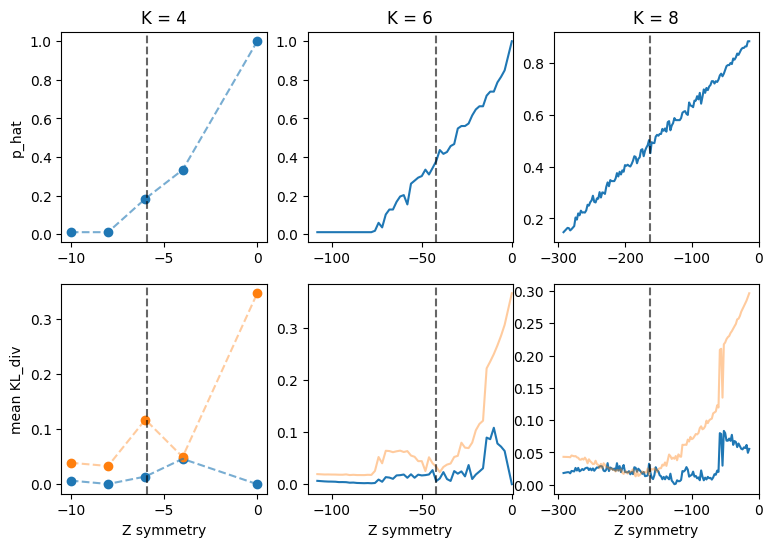

In [112]:
fig, ax = plt.subplots(2, 3, figsize = (3 * 3, 3 * 2))

for j, h in enumerate([2, 3, 4]):
    for i in range(2):
        if h == 2:
            ax[i, j].plot(ht[h].keys(), [ht[h][score][i] for score in ht[h]], ls = "--", alpha = 0.6)
            ax[i, j].scatter(ht[h].keys(), [ht[h][score][i] for score in ht[h]])
        else:
            ax[i, j].plot(ht[h].keys(), [ht[h][score][i] for score in ht[h]])
            
        if i == 1:
            if h == 2:
                ax[i, j].plot(ht[h].keys(), [ht[h][score][2] for score in ht[h]], ls = "--", alpha = 0.4)
                ax[i, j].scatter(ht[h].keys(), [ht[h][score][2] for score in ht[h]])
            else:
                ax[i, j].plot(ht[h].keys(), [ht[h][score][2] for score in ht[h]], alpha = 0.4)
            ax[i, j].set_xlabel("Z symmetry")
            
        if i == 0:
            ax[i, j].set_title(f"K = {2 * h}")

        # ax[i, j].scatter(ht_defaults[h][0], ht_defaults[h][1][i])
        
        ax[i, j].axvline(ht_k_closest_to_mean[2*h], c = 'k', ls = "--", alpha = 0.6)
        ax[i, j].set_xlim((min(ht[h].keys()) * 1.05, 0 + 0.5))        

    if j == 0:
        ax[0, j].set_ylabel("p_hat")
        ax[1, j].set_ylabel("mean KL_div")
        
fig.savefig(
    "/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/Z_symmetry_vs_p_hat_kl_div_bin_dist.pdf",
    bbox_inches = "tight"
)

In [108]:
ht_defaults

{2: (-8, (0.01, 0.003014451871165816, 0.035248404496137926)),
 3: (-108, (0.01, 0.008524378773200511, 0.020908228943372974)),
 4: (-576, (0.01, 0.012334765069229429, 0.015700982660624436))}